#Pytorch e Librerie

In [ ]:
!nvidia-smi

Fri Dec 10 10:06:10 2021       
+-----------------------------------------------------------------------------+
| NVIDIA-SMI 495.44       Driver Version: 460.32.03    CUDA Version: 11.2     |
|-------------------------------+----------------------+----------------------+
| GPU  Name        Persistence-M| Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp  Perf  Pwr:Usage/Cap|         Memory-Usage | GPU-Util  Compute M. |
|                               |                      |               MIG M. |
|===============================+======================+======================|
|   0  Tesla K80           Off  | 00000000:00:04.0 Off |                    0 |
| N/A   71C    P8    32W / 149W |      0MiB / 11441MiB |      0%      Default |
|                               |                      |                  N/A |
+-------------------------------+----------------------+----------------------+
                                                                               
+-------

In [ ]:
import scipy.io as sio
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import itertools
from torch.optim import lr_scheduler
import numpy as np
import torchvision
from torchvision import datasets, models, transforms
import matplotlib.pyplot as plt
import time
import os
import shutil
import copy
from sklearn.metrics import confusion_matrix
from random import shuffle
import torchvision.utils as vutils
import matplotlib.pyplot as plt
from torch.autograd import Variable
from random import choice, sample, seed, randint, random, gauss
import torch.nn.functional as F
from scipy.io import loadmat
from torch.utils.data import ConcatDataset, DataLoader
from torchvision.datasets import DatasetFolder
from torchvision.transforms import Compose, CenterCrop, RandomCrop, RandomHorizontalFlip, ToTensor, ToPILImage, Grayscale


#rendere l'esecuzione deterministica
torch.manual_seed(0)
np.random.seed(0)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


#Definizione Reti

##Generatore

In [ ]:
class Generator(nn.Module):
    # initializers
    def __init__(self, num_classes, n_channel, noise_size, d=128, ):
        super(Generator, self).__init__()

        self.input_noise = nn.Sequential(
            nn.ConvTranspose2d(noise_size, d * 4, 4, 2, 0, bias=False),
            nn.BatchNorm2d(d * 4),
            nn.ReLU(True),
        )

        self.input_label = nn.Sequential(
            nn.ConvTranspose2d(num_classes, d * 4, 4, 2, 0, bias=False),
            nn.BatchNorm2d(d * 4),
            nn.ReLU(True),
        )

        self.main = nn.Sequential(
            nn.ConvTranspose2d(d * 8, d * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(d * 4),
            nn.ReLU(True),

            nn.ConvTranspose2d(d * 4, d * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(d * 2),
            nn.ReLU(True),

            nn.ConvTranspose2d(d * 2, d, 4, 2, 1, bias=False),
            nn.BatchNorm2d(d),
            nn.ReLU(True),

            nn.ConvTranspose2d(d, n_channel, 4, 2, 1, bias=False),
            nn.Tanh()

        )

    # forward method
    def forward(self, input, label):
        x = self.input_noise(input)
        y = self.input_label(label)
        #print('Noise')
        #print(x.shape)
        #print('Label')
        #print(y.shape)
        x = torch.cat([x, y], 1)    #concateno lungo i canali
        #print('insieme')
        #print(x.shape)
        x = self.main(x)
        #print(x.shape)
        #La tanhH dice di normalizzare i dati rispetto a -1 e 1

        return x

## Discriminator Net

In [ ]:
#Discriminatore
class Discriminator(nn.Module):
    # initializers
    def __init__(self, num_classes, n_channel, d=128):
        super(Discriminator, self).__init__()

        self.input_img = nn.Sequential(
            nn.Conv2d(n_channel, int(d / 2), 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True)

        )
        self.input_label = nn.Sequential(
            nn.Conv2d(num_classes, int(d / 2), 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True)

        )

        self.main = nn.Sequential(
            nn.Conv2d(d, d * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(d*2),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(d * 2, d * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(d * 4),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(d * 4, d * 8, 4, 2, 1, bias=False),
            nn.BatchNorm2d(d * 8),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(d * 8, 1, 4, 1, 0, bias=False),

            nn.Sigmoid()
        )

    # forward method
    def forward(self, input, label):
        x = self.input_img(input)
        y = self.input_label(label)
        #print('image')
        #print(x.shape)
        #print('label')
        #print(y.shape)
        x = torch.cat([x, y], 1)
        #print('insieme')
        #print(x.shape)
        x = self.main(x)
        #print(x.shape)
        return x.squeeze()


#Pre-Processing

In [ ]:
!cp drive/My\ Drive/DataMining_EsercitazioneDeepLearning/flower_photos.zip /content/
!unzip flower_photos.zip  -d /content/

Archive:  flower_photos.zip
   creating: /content/flower_photos/
   creating: /content/flower_photos/daisy/
  inflating: /content/flower_photos/daisy/100080576_f52e8ee070_n.jpg  
  inflating: /content/flower_photos/daisy/10140303196_b88d3d6cec.jpg  
  inflating: /content/flower_photos/daisy/10172379554_b296050f82_n.jpg  
  inflating: /content/flower_photos/daisy/10172567486_2748826a8b.jpg  
  inflating: /content/flower_photos/daisy/10172636503_21bededa75_n.jpg  
  inflating: /content/flower_photos/daisy/102841525_bd6628ae3c.jpg  
  inflating: /content/flower_photos/daisy/1031799732_e7f4008c03.jpg  
  inflating: /content/flower_photos/daisy/10391248763_1d16681106_n.jpg  
  inflating: /content/flower_photos/daisy/10437754174_22ec990b77_m.jpg  
  inflating: /content/flower_photos/daisy/10437770546_8bb6f7bdd3_m.jpg  
  inflating: /content/flower_photos/daisy/10437929963_bc13eebe0c.jpg  
  inflating: /content/flower_photos/daisy/10466290366_cc72e33532.jpg  
  inflating: /content/flower_phot

#Funzioni di utilità

In [ ]:
def count_parameters(model):
  return sum(p.numel() for p in model.parameters() if p.requires_grad)


#Utility Function
#Inizializzazione dei pesi
def weights_init(m):
    classname = m.__class__.__name__
    if classname.find('Conv') != -1:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif classname.find('BatchNorm') != -1:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)


def show_result(num_epoch, fixed_z_, fixed_y_label_, G, ImagesForClass,  num_classes,  show = False, save = False, path = 'result.png'):
  #il generatore deve essere in modalità di eval!
  #una riga per ogni classe
  test_images = G(fixed_z_, fixed_y_label_)

  fig, ax = plt.subplots(num_classes, ImagesForClass, figsize=(10, 10))

  for i, j in itertools.product(range(num_classes), range(ImagesForClass)):
    ax[i, j].get_xaxis().set_visible(False)
    ax[i, j].get_yaxis().set_visible(False)

  for i, j in itertools.product(range(num_classes), range(ImagesForClass)):
    k = ImagesForClass* i + j
    ax[i, j].cla()
    ax[i, j].imshow((test_images[k].cpu().data.numpy().transpose(1, 2, 0) + 1) / 2)   #per riportare i dati tr 0 e 1

  label = 'Epoch {0}'.format(num_epoch)
  fig.text(0.5, 0.04, label, ha='center')

  if save:
    plt.savefig(path)

  if show:
    plt.show()
  else:
    plt.close()


def show_train_hist_loss(hist, show = False, save = False, path = 'Train_hist.png'):
    x = range(len(hist['D_losses_on_fake']))

    y1 = hist['D_losses_on_fake']
    y2 = hist['D_losses_on_real']
    y3 = hist['G_losses']

    plt.plot(x, y1, label='D_losses_on_fake')
    plt.plot(x, y2, label='D_losses_on_real')
    plt.plot(x, y3, label='G_losses')
    plt.xlabel('Epoch')
    plt.ylabel('Losses')

    plt.legend(loc=4)
    plt.grid(True)
    plt.tight_layout()

    if save:
        plt.savefig(path)

    if show:
        plt.show()
    else:
        plt.close()



def show_train_hist_pred(hist, show = False, save = False, path = 'Train_hist.png'):
    x = range(len(hist['D_pred_on_fake']))

    y1 = hist['D_pred_on_fake']
    y2 = hist['D_pred_on_real']
    y3 = hist['G_pred_Step']


    plt.plot(x, y1, label='D_pred_on_fake')
    plt.plot(x, y2, label='D_pred_on_real')
    plt.plot(x, y3, label='G_pred_Step')


    plt.xlabel('Epoch')
    plt.ylabel('Predictions')

    plt.legend(loc=4)
    plt.grid(True)
    plt.tight_layout()

    if save:
        plt.savefig(path)

    if show:
        plt.show()
    else:
        plt.close()

#Data Manager

Le immagini che abbiamo in ingresso, devono essere:


1.   Riportate a 64x64
2.   Normalizzate tra -1 e 1



In [ ]:
#Data Manager
#trasformazioni da applicare

img_size = 64
n_channel = 3
noise_size = 100

base_dataPath = 'flower_photos'

transform = Compose([transforms.Resize((img_size,img_size)),
                     RandomHorizontalFlip(),
                     ToTensor(),
                     transforms.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))])

dataset = datasets.ImageFolder(root = base_dataPath, transform=transform, target_transform=None)
num_classes = len(dataset.classes)
print(dataset)

print(dataset.classes)


Dataset ImageFolder
    Number of datapoints: 3670
    Root location: flower_photos
    StandardTransform
Transform: Compose(
               Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=None)
               RandomHorizontalFlip(p=0.5)
               ToTensor()
               Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
           )
['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


#Preparazione delle labels

In [ ]:
#Definizione delle label da dare in input al generatore.
#-----> Input per Generatore
#Abbiamo 5 classi, quindi 5 vettori, in verticale, one hot encoding
onehot = torch.zeros(num_classes, num_classes)
onehot = onehot.scatter_(1, torch.LongTensor(list(range(num_classes))).view(num_classes,1), 1).view(num_classes, num_classes, 1, 1)


#-----> Input per Discriminatore
#Dobbiamo organizzare le label su due dimensioni
#abbiamo tanti volumi 3D quante sono le classi
#Un volume riferito alla label i-esima, ha l'iesima matrice pari a uno.

fill = torch.zeros([num_classes, num_classes, img_size, img_size])
for i in range(num_classes):
    fill[i, i, :, :] = 1


#Fixed Noise

Ci conserviamo un rumore in modo da vedere come le immagini evolvono durante l'addestramento

In [ ]:
#Numero di immagini per classe
nImages = 4
#Dallo stesso rumore voglio far uscire classi differenti.

temp_z0_ = torch.randn(int(nImages/2), noise_size)
temp_z1_ = torch.randn(int(nImages/2), noise_size)

fixed_z_ = torch.cat([temp_z0_,
                      temp_z1_,
                      temp_z0_,
                      temp_z1_,
                      temp_z0_,
                      temp_z1_,
                      temp_z0_,
                      temp_z1_,
                      temp_z0_,
                      temp_z1_], 0) #20x100

fixed_y_ = torch.cat([0*torch.ones(nImages), torch.ones(nImages),
                      2*torch.ones(nImages), 3*torch.ones(nImages),
                      4*torch.ones(nImages)], 0).type(torch.LongTensor).squeeze()

fixed_z_ = fixed_z_.view(-1, noise_size, 1, 1)


fixed_y_label_ = onehot[fixed_y_]
fixed_z_ = fixed_z_.cuda()
fixed_y_label_ = fixed_y_label_.cuda()

#Train Loop

##Inizializzazione

Generatore:  3187584
Discriminatore:  2766592
Generator(
  (input_noise): Sequential(
    (0): ConvTranspose2d(100, 256, kernel_size=(4, 4), stride=(2, 2), bias=False)
    (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (input_label): Sequential(
    (0): ConvTranspose2d(5, 256, kernel_size=(4, 4), stride=(2, 2), bias=False)
    (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (main): Sequential(
    (0): ConvTranspose2d(512, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(

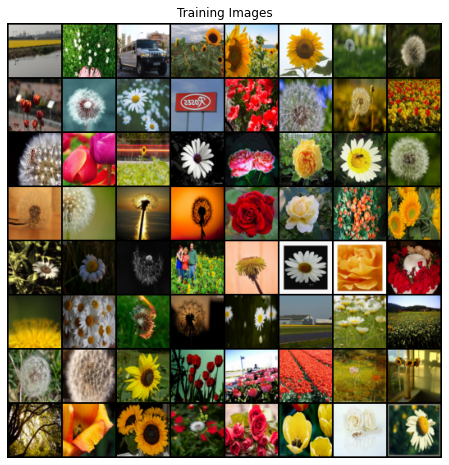

In [ ]:
# training parameters
batch_size = 64
lr = 0.0001
train_epoch = 500

Num_filters = 64

#Definizione delle reti
G = Generator( num_classes= num_classes, n_channel= n_channel, noise_size=noise_size, d = Num_filters)
D = Discriminator(num_classes = num_classes, n_channel=n_channel,  d = Num_filters)

#inizializzazione dei pesi
G.apply(weights_init)
D.apply(weights_init)
G = G.cuda()
D = D.cuda()

gen = count_parameters(G)
dis = count_parameters(D)
print('Generatore: ', gen)
print('Discriminatore: ', dis)

# Binary Cross Entropy loss
BCE_loss = nn.BCELoss()

# Adam optimizer
G_optimizer = optim.Adam(G.parameters(), lr=lr, betas=(0.5, 0.999))
D_optimizer = optim.Adam(D.parameters(), lr=lr, betas=(0.5, 0.999))


train_hist = {}
train_hist['D_losses_on_fake'] = []    #tiene conto della loss del Discriminatore sui dati fake
train_hist['D_losses_on_real'] = []    #tiene conto della loss del Discriminatore sui dati real
train_hist['G_losses'] = []            #tiene conto della loss del Generatore

train_hist['D_pred_on_fake'] = []     #predizione di D sui fake
train_hist['D_pred_on_real'] = []     #predizione di D sui reali
train_hist['G_pred_Step'] = []        #predizione di D durante l'addestramento del generatore


print(G)
print(D)

# Plot some training images
TrainLoader = DataLoader(dataset, shuffle=True, batch_size= batch_size)
real_batch = next(iter(TrainLoader))
plt.figure(figsize=(8,8))
plt.axis("off")
plt.title("Training Images")
plt.imshow(np.transpose(vutils.make_grid(real_batch[0].cuda()[:64], padding=2, normalize=True).cpu(),(1,2,0)))


## Loop

In [ ]:
for epoch in range(1, train_epoch + 1 ):

  D_losses_on_real = 0.0
  D_losses_on_fake = 0.0
  G_losses = 0.0

  D_pred_on_real = 0
  D_pred_on_fake = 0
  G_pred_step = 0

  data_size = 0

  G.train()
  D.train()

  for x, label in TrainLoader:

    #--------------------------------------------------------------------------- train Discriminator
    mini_batch = x.size(0)
    data_size += mini_batch

    y_real = torch.ones(mini_batch).cuda()   #tutti uno
    y_fake = torch.zeros(mini_batch).cuda()   #tutti zero

    #reset dei gradienti
    D.zero_grad()
    D_optimizer.zero_grad()

    #------------------ STEP ON REAL IMAGES
    #label encoding
    y_fill_ = fill[label].cuda()
    x = x.cuda()
    Dpred_on_real = D(x, y_fill_)
    Dloss_on_real = BCE_loss(Dpred_on_real, y_real)

    #------------------ STEP ON FAKE IMAGES
    #label encoding
    #uso le label che sono state usata nelle real images
    y_oneHot = onehot[label].cuda()
    z = torch.randn((mini_batch, noise_size)).view(-1, noise_size, 1, 1).cuda() #128x100x1x1
    Gen_images = G(z, y_oneHot)
    #label per le immagini generate
    y_fill_fake = fill[label].cuda()
    Dpred_on_fake = D(Gen_images.detach(), y_fill_fake)
    Dloss_on_fake = BCE_loss(Dpred_on_fake, y_fake)

    #------------------ Update param
    #print('D Update param')
    Dtot_loss = 0.5*(Dloss_on_real +  Dloss_on_fake)
    Dtot_loss.backward()
    D_optimizer.step()

    #------------------Statistics
    DpredlabR = (Dpred_on_real > 0.5).float()
    D_pred_on_real +=  (y_real == DpredlabR.cuda()).type(torch.DoubleTensor).sum().item()
    DpredFake = (Dpred_on_fake > 0.5).float()
    D_pred_on_fake +=  (y_fake == DpredFake.cuda()).type(torch.DoubleTensor).sum().item()
    D_losses_on_real += Dloss_on_real.item()*mini_batch
    D_losses_on_fake += Dloss_on_fake.item()*mini_batch

    #------------------------------------train Generator
    G.zero_grad()
    G_optimizer.zero_grad()

    #Conserviamo lo stesso rumore di prima
    #z = torch.randn((mini_batch, noise_size)).view(-1, noise_size, 1, 1).cuda()
    #Gen_images = G(z, y_oneHot)


    Dpred_on_fake_again = D(Gen_images, y_fill_fake)
    #vogliamo che il generatore si addestri in modo che la sua uscita
    #sia interpretata come vera del discriminatore
    Gloss = BCE_loss(Dpred_on_fake_again, y_real)  #quindi considero l'uscita pari a 1

    #------------------ Update param
    #print('g update')
    Gloss.backward()
    G_optimizer.step()

    #------------------ Statistics
    G_losses += Gloss.item()*mini_batch
    GpredlabF = (Dpred_on_fake_again > 0.5).float()
    G_pred_step += (y_real == GpredlabF.cuda()).type(torch.DoubleTensor).sum().item()

  #At the end of each epochs
  AVGDlossFake= D_losses_on_fake/data_size
  AVGDlossReal= D_losses_on_real/data_size
  AVGGloss= G_losses/data_size
  AVGDpredR =  D_pred_on_real/data_size
  AVGDpredF =  D_pred_on_fake/data_size
  AVGDpredGS = G_pred_step/data_size

  train_hist['D_losses_on_fake'].append(AVGDlossFake)
  train_hist['D_losses_on_real'].append(AVGDlossReal)
  train_hist['G_losses'].append(AVGGloss)
  train_hist['D_pred_on_real'].append(AVGDpredR)
  train_hist['D_pred_on_fake'].append(AVGDpredF)
  train_hist['G_pred_Step'].append(AVGDpredGS)

  print('[Epoch %d][Dnet [LossReal: %.4f  LossFake: %.4f -- PredReal: %.4f  PredFake: %.4f]][Gnet Loss: %.4f Pred: %.4f]'
        %(epoch, AVGDlossReal, AVGDlossFake, AVGDpredR, AVGDpredF, AVGGloss, AVGDpredGS))

  if epoch % 10 == 0:
  #if epoch % 10 == 0 and epoch > 50:
    #vediamo come ci comportiamo sul rumore che avevamo escluso
    G.eval()
    show_result(epoch, fixed_z_, fixed_y_label_, G, nImages,  num_classes,  show = True, save = False, path = '')
    #plot dei grafici
    show_train_hist_loss(train_hist, show = True, save = False, path = '')
    show_train_hist_pred(train_hist, show = True, save = False, path = '')